 **Practical 10: PCA**

**Aim**:

To understand and implement Principal Component Analysis (PCA) using the Wine dataset and reduce the dimensionality of data while retaining maximum possible information.

**Objectives**:

1. To understand the concept and importance of Principal Component Analysis.
2. To explore the Wine dataset using descriptive statistics.
3. To visualize data using boxplots and scatterplots.
4. To calculate and understand the covariance matrix.
5. To standardize the dataset using StandardScaler.
6. To apply PCA to reduce the number of features.
7. To understand principal components and explained variance.
8. To visualize the wine classes using principal components.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine

# Load Wine dataset
wine = load_wine()

df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target



**Step 1: Display basic statistics using describe()**

In [3]:
# Display basic statistics
print(df.describe())

          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   
min         0.9

**Explanation**: The describe() function displays count, mean, standard deviation, minimum, maximum, and quartiles for each numerical feature.

**Step 2: Boxplot by output labels/classes**

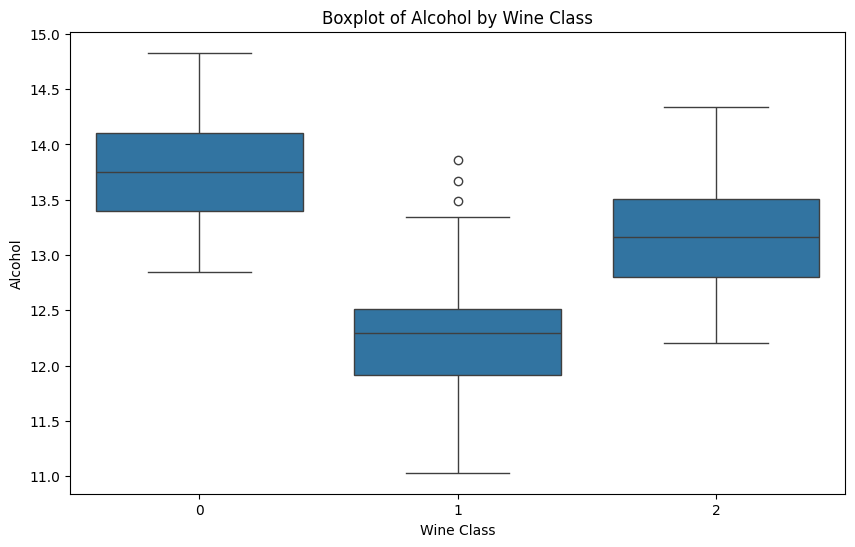

In [4]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="target",
    y="alcohol"
)

plt.title("Boxplot of Alcohol by Wine Class")
plt.xlabel("Wine Class")
plt.ylabel("Alcohol")
plt.show()

**Explanation**: The boxplot compares the alcohol content across the three wine classes. It displays the median, quartiles, spread, and potential outliers.

**Step 3: Scatterplot using two variables**

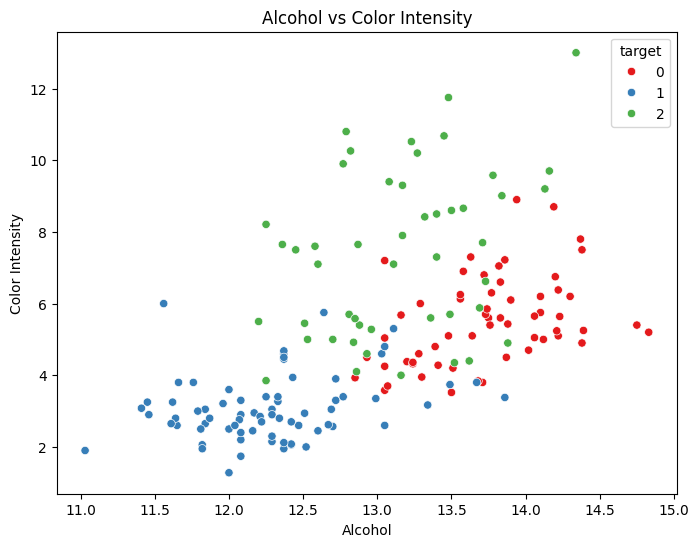

In [5]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="alcohol",
    y="color_intensity",
    hue="target",
    palette="Set1"
)

plt.title("Alcohol vs Color Intensity")
plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")
plt.show()

**Explanation**: The scatterplot shows the relationship between alcohol and color intensity. Different colors represent the three wine classes, allowing us to examine how well these features distinguish them.

**Step 4: Plot covariance matrix**

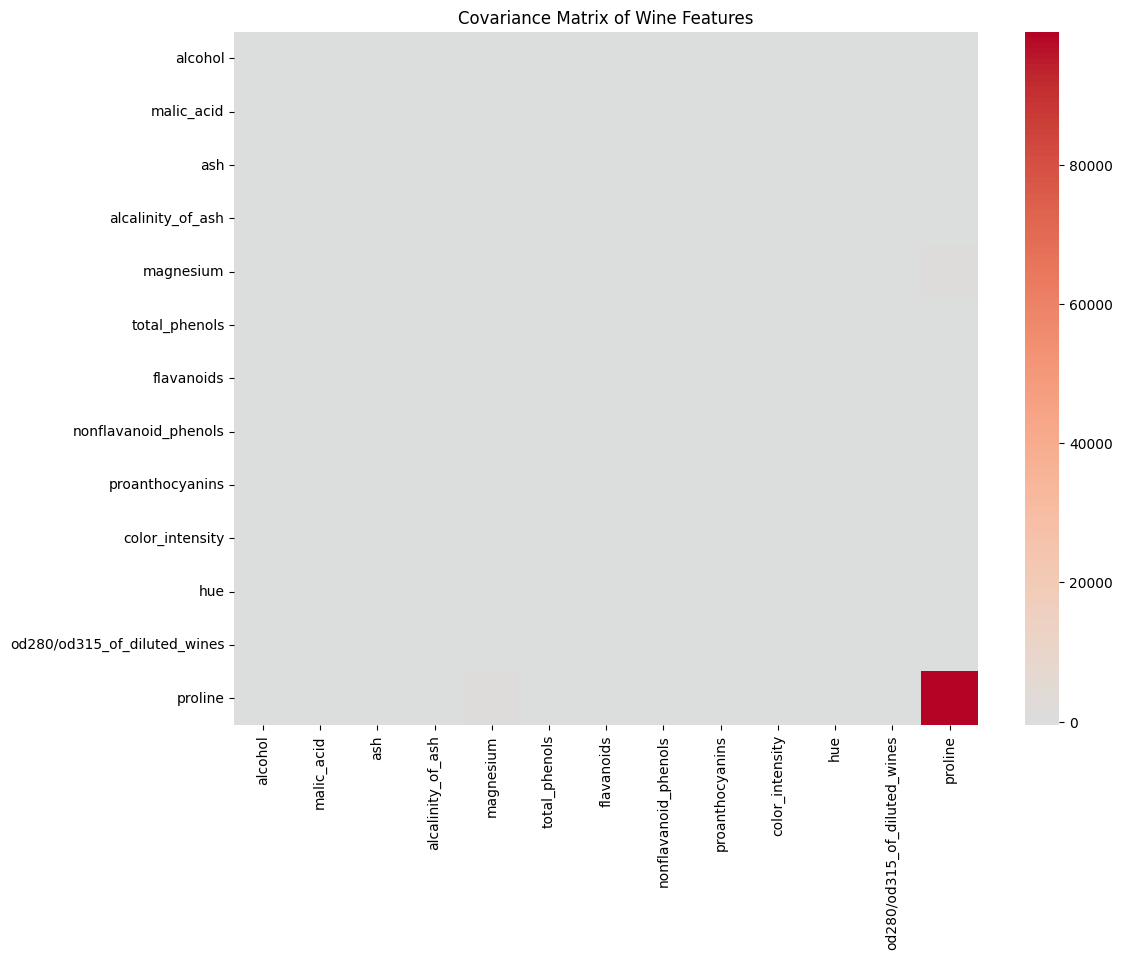

In [13]:
# Calculate covariance matrix for the features
cov_matrix = df.drop(columns="target").cov()

plt.figure(figsize=(12, 9))

sns.heatmap(
    cov_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)


plt.title("Covariance Matrix of Wine Features")
plt.show()

**Explanation**: The covariance matrix measures how pairs of features vary together.

Positive covariance: both features tend to increase together.

Negative covariance: one feature tends to increase as the other decreases.

Covariance near zero: little linear co-variation.

Because features have different units and ranges, the covariance values may vary greatly.

**Step 5: Data scaling**

In [7]:
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = wine.data
y = wine.target

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert scaled data into a DataFrame
scaled_df = pd.DataFrame(
    X_scaled,
    columns=wine.feature_names
)

print(scaled_df.head())

# Check the scaled feature means
print("\nFeature Means After Scaling:")
print(scaled_df.mean().round(2))

# Check the scaled feature standard deviations
print("\nFeature Standard Deviations After Scaling:")
print(scaled_df.std().round(2))

    alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
0  1.518613   -0.562250  0.232053          -1.169593   1.913905   
1  0.246290   -0.499413 -0.827996          -2.490847   0.018145   
2  0.196879    0.021231  1.109334          -0.268738   0.088358   
3  1.691550   -0.346811  0.487926          -0.809251   0.930918   
4  0.295700    0.227694  1.840403           0.451946   1.281985   

   total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
0       0.808997    1.034819             -0.659563         1.224884   
1       0.568648    0.733629             -0.820719        -0.544721   
2       0.808997    1.215533             -0.498407         2.135968   
3       2.491446    1.466525             -0.981875         1.032155   
4       0.808997    0.663351              0.226796         0.401404   

   color_intensity       hue  od280/od315_of_diluted_wines   proline  
0         0.251717  0.362177                      1.847920  1.013009  
1        -0.293321  0.406051

**Explanation**: StandardScaler transforms each feature to approximately zero mean and unit variance. Scaling is important for PCA because features with larger numerical ranges could otherwise dominate the analysis.

**Step 6: Show better class separation using Principal Components**

PCA reduces the 13 original wine features to three principal components, making the data easier to visualize.

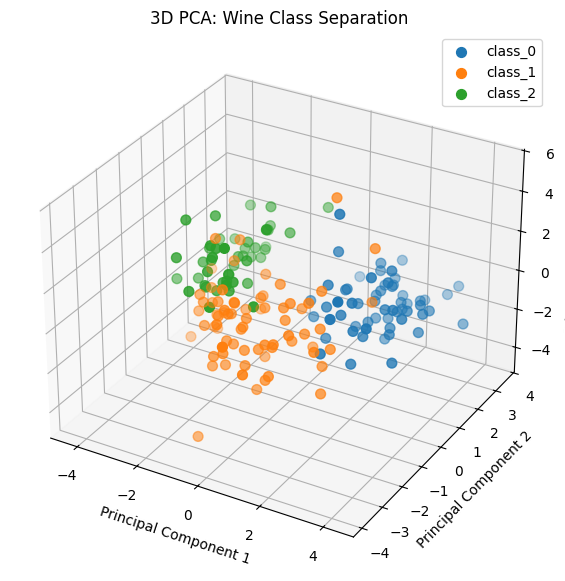

Explained Variance Ratio: [0.36198848 0.1920749  0.11123631]
Total Variance Explained: 66.53 %

Individual Variance Explained:
PC1: 36.20%
PC2: 19.21%
PC3: 11.12%


In [11]:
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D

# Apply PCA to scaled data
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame for visualization
pca_df = pd.DataFrame(
    X_pca,
    columns=[
        "Principal Component 1",
        "Principal Component 2",
        "Principal Component 3"
    ]
)

pca_df["target"] = y

# Plot PCA results in 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

for i, name in enumerate(wine.target_names):
    mask = pca_df["target"] == i

    ax.scatter(
        pca_df.loc[mask, "Principal Component 1"],
        pca_df.loc[mask, "Principal Component 2"],
        pca_df.loc[mask, "Principal Component 3"],
        label=name,
        s=50
    )

ax.set_title("3D PCA: Wine Class Separation")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
ax.legend()

plt.show()

# Display explained variance
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print(
    "Total Variance Explained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)
print("\nIndividual Variance Explained:")
for i, variance in enumerate(pca.explained_variance_ratio_, start=1):
         print(f"PC{i}: {variance * 100:.2f}%")


**Explanation**:

PCA creates new variables called principal components from the original features.

- PC1: Captures the maximum possible variance in the dataset.
- PC2: Captures the maximum remaining variance.
- PC3: Captures the next highest remaining variance.

The principal components are uncorrelated with each other.

The 3D graph shows the distribution of the three wine classes using the first three principal components.

The explained variance ratio tells us how much information or variation is retained by each principal component.

**Conclusion**:

In this practical, we studied Principal Component Analysis (PCA) using the Wine dataset.

We performed exploratory data analysis using descriptive statistics, boxplots, scatterplots, and a covariance matrix.

The features were standardized using StandardScaler, and PCA was applied to reduce the original 13 features to three principal components.

We also created a 3D visualization to understand the distribution of different wine classes and examined the explained variance ratio.

This practical helped us understand how PCA reduces the dimensions of a dataset while preserving important information.